In [40]:
import numpy as np
import pandas as pd
import itertools
import pubmed_parser as pp
from pathlib import Path
import matplotlib.pyplot as plt
from datetime import date
import re
from tqdm import tqdm
import time
from pybedtools import BedTool
import random
import math
today = date.today()

# Create Preset Ranges for Closest Genes

In [41]:
genes_in_both = pd.read_pickle('../data/STRING-and-Alex-genes.pkl')

chromosomes = {
    'chr1': 249250621,
    'chr2': 243199373,
    'chr3': 198022430,
    'chr4': 191154276,
    'chr5': 180915260,
    'chr6': 171115067,
    'chr7': 159138663,
    'chr8': 146364022,
    'chr9': 141213431,
    'chr10': 135534747,
    'chr11': 135006516,
    'chr12': 133851895,
    'chr13': 115169878,
    'chr14': 107349540,
    'chr15': 102531392,
    'chr16': 90354753,
    'chr17': 81195210,
    'chr18': 78077248,
    'chr19': 59128983,
    'chr20': 63025520,
    'chr21': 48129895,
    'chr22': 51304566,
    'chrX': 155270560,
    'chrY': 59373566
}

def randomGenCoord():
    chrm = random.choice(list(chromosomes))
    coord = random.randint(0, chromosomes[chrm])
    return chrm + ' ' + str(coord)
# print(randomGenCoord())

def findNearestGene(coord, gene_ranges):
    print(coord)
    
    # Subset genes_df to just same chromosome
    coord = coord.split(' ')
    chrm = coord[0]
    coord = int(coord[1])
    
    chrm_range = gene_ranges[chrm]
    chrm_range_list = list(chrm_range)
    
    for i, interval in enumerate(chrm_range_list):
        if coord in range(interval[0], interval[1]):
            return chrm_range[interval]
    
    
#     idx_lower = 0
#     idx_upper = len(chrm_range_list)
    
#     while idx_upper > idx_lower:
#         mid_idx = (idx_upper - idx_lower) // 2
#         if coord in range(chrm_range_list[mid_idx][0], chrm_range_list[mid_idx][1]):
#             return chrm_range[chrm_range_list[mid_idx]]
#         elif coord > chrm_range_list[mid_idx][1]:
#             idx_lower = mid_idx+1
#         elif coord < chrm_range_list[mid_idx][0]:
#             idx_upper = mid_idx
    
#     return 'These coordinates are not valid.'
  

def generate_ROI_url(fn):
    return 'https://epilogos.altius.org:3001/?application=viewer&mode=single&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~stsai%2F' + fn

In [42]:
## READ IN BED FILE WITH COORDINATES

gene_df = pd.read_csv('../data/hg19.gencode.v19.annotation.hgnc.longest.gtf.bed14',
                      delimiter='\t', header = None, index_col=3)

gene_df = gene_df.rename({3:'gene_names', 0:'chr', 1:'start', 2:'end', 5:'strand', 9:'descriptor'}, axis=1)
gene_df.index = gene_df.index.rename('gene_names')

# Remove duplicate genes
gene_df_no_dupes = gene_df[~gene_df.index.duplicated(keep='first')]
print(gene_df_no_dupes.shape, gene_df.shape)

# Remove duplicate genes from 'genes_in_both'
genes_in_both_df = gene_df_no_dupes.loc[genes_in_both.preferred_name.tolist()].reset_index()
genes_in_both_dup_removed = genes_in_both_df.drop_duplicates(subset=['gene_names'])
print(genes_in_both_df.shape, genes_in_both_dup_removed.shape)

(51806, 13) (52739, 13)
(18059, 14) (18059, 14)


In [43]:
# CALCULATED GENE RANGES

# gene_ranges = {}

# for chrm in chromosomes.keys():
#     chrm_genes = genes_in_both_dup_removed[genes_in_both_dup_removed['chr'] == chrm].sort_values(by='start')
#     start = 0
#     chrm_dict = {}
#     for i in range(1, len(chrm_genes)):
#         gene1 = chrm_genes.iloc[i-1, :]
#         gene2 = chrm_genes.iloc[i, :]
        
#         diff = (gene2.start - gene1.end)//2
#         chrm_dict[(start, gene1.end+diff)] = gene1.gene_names
#         start = gene2.start - diff
    
#     chrm_dict[(start, chromosomes[chrm])] = gene2.gene_names
#     gene_ranges[chrm] = chrm_dict


In [44]:
# # load pickle module
# import pickle

# # create a binary pickle file 
# f = open("../data/gene_ranges.pkl","wb")

# # write the python object (dict) to pickle file
# pickle.dump(gene_ranges,f)

# # close file
# f.close()

file_to_read = open('../data/gene_ranges.pkl', "rb")

gene_ranges = pickle.load(file_to_read)
gene_ranges

{'chr1': {(0, 218823): 'OR4F5',
  (218824, 494846): 'OR4F29',
  (494846, 741585): 'OR4F16',
  (741585, 879769): 'SAMD11',
  (879769, 895318): 'NOC2L',
  (895318, 901485): 'KLHL17',
  (901486, 910533): 'PLEKHN1',
  (910533, 925919): 'PERM1',
  (925919, 942177): 'HES4',
  (942177, 952711): 'ISG15',
  (952711, 998920): 'AGRN',
  (998921, 1013444): 'RNF223',
  (1013445, 1080380): 'C1orf159',
  (1080380, 1136102): 'TTLL10',
  (1136103, 1144388): 'TNFRSF18',
  (1144388, 1150911): 'TNFRSF4',
  (1150911, 1167519): 'SDF4',
  (1167520, 1179854): 'B3GALT6',
  (1179855, 1212524): 'UBE2J2',
  (1212524, 1227577): 'SCNN1D',
  (1227577, 1243672): 'ACAP3',
  (1243672, 1253601): 'PUSL1',
  (1253602, 1265485): 'CPTP',
  (1265485, 1270670): 'TAS1R3',
  (1270671, 1286400): 'DVL1',
  (1286401, 1303133): 'MXRA8',
  (1303133, 1316374): 'AURKAIP1',
  (1316375, 1335989): 'CCNL2',
  (1335990, 1348246): 'MRPL20',
  (1348246, 1359328): 'ANKRD65',
  (1359328, 1367108): 'TMEM88B',
  (1367109, 1381665): 'VWA1',
  (13

In [46]:
print(findNearestGene(randomGenCoord(), gene_ranges))

chr7 90048049
CLDN12


**READ IN PROTEIN ASSOCIATIONS**

Downloaded from STRING https://string-db.org/cgi/download?sessionId=inputgtsessionId&species_text=Homo+sapiens

In [47]:
# protein_info_df = pd.read_csv('../data/Literature_Search/9606.protein.info.v11.5.txt', delimiter='\t', index_col=0)

# genes_in_both = protein_info_df[protein_info_df['preferred_name'].isin(gene_names)]

# gene_ids = genes_in_both.index
# print(genes_in_both)
# genes_in_both.to_pickle('../data/Literature_Search/STRING-and-Alex-genes.pkl')


# protein_assoc_df = pd.read_csv('../data/Literature_Search/9606.protein.links.v11.5.txt', delimiter=' ', index_col=0)
# print(protein_assoc_df.shape)


# protein_assoc_sub = protein_assoc_df[protein_assoc_df['protein2'].isin(gene_ids)]
# protein_assoc_sub = protein_assoc_sub[protein_assoc_sub.index.isin(gene_ids)]

In [48]:
## READ IN STRING ASSOCIATIONS

genes_in_both_no_dupes = genes_in_both.drop_duplicates(subset='preferred_name')
print(genes_in_both.shape, genes_in_both_no_dupes.shape)

protein_assoc_df = pd.read_csv('../data/9606.protein.physical.links.full.v11.5.txt', delimiter=' ', index_col=0)
gene_ids = genes_in_both.index
protein_assoc_sub = protein_assoc_df[protein_assoc_df['protein2'].isin(gene_ids)]
protein_assoc_sub = protein_assoc_sub[protein_assoc_sub.index.isin(gene_ids)]
protein_assoc_sub['protein1_pref'] = protein_assoc_sub.index.map(genes_in_both['preferred_name'])
protein_assoc_sub['protein2_pref'] = protein_assoc_sub['protein2'].map(genes_in_both['preferred_name'])

print(genes_in_both.columns)
print(protein_assoc_sub.columns)

(18059, 3) (18059, 3)
Index(['preferred_name', 'protein_size', 'annotation'], dtype='object')
Index(['protein2', 'homology', 'experiments', 'experiments_transferred',
       'database', 'database_transferred', 'textmining',
       'textmining_transferred', 'combined_score', 'protein1_pref',
       'protein2_pref'],
      dtype='object')


In [49]:
# SEARCH FOR SPECIFIC GENE
# gene = 'GATA1'
# specific_gene_df = protein_assoc_sub[protein_assoc_sub['protein1_pref'] == gene].sort_values('combined_score', ascending=False)

# USE RANDOM COORDINATE 
gene = findNearestGene(randomGenCoord(), gene_ranges)
print(gene)
specific_gene_df = protein_assoc_sub[protein_assoc_sub['protein1_pref'] == gene].sort_values('combined_score', ascending=False)

chr1 116003509
NGF


In [50]:
specific_gene_df

,protein2,homology,experiments,experiments_transferred,database,database_transferred,textmining,textmining_transferred,combined_score,protein1_pref,protein2_pref
protein1,,,,,,,,,,,
9606.ENSP00000358525,9606.ENSP00000431418,0,933,53,900,0,898,467,999,NGF,NTRK1
9606.ENSP00000358525,9606.ENSP00000172229,0,566,233,900,0,898,129,996,NGF,NGFR
9606.ENSP00000358525,9606.ENSP00000256637,0,566,164,900,0,866,58,994,NGF,SORT1
9606.ENSP00000358525,9606.ENSP00000401303,0,0,0,900,0,474,0,945,NGF,SHC1
9606.ENSP00000358525,9606.ENSP00000244007,0,0,0,900,0,400,0,937,NGF,PLCG1
...,...,...,...,...,...,...,...,...,...,...,...
9606.ENSP00000358525,9606.ENSP00000445768,0,0,0,0,0,159,0,158,NGF,KIAA1147
9606.ENSP00000358525,9606.ENSP00000379287,0,0,0,0,0,156,0,155,NGF,YWHAZ
9606.ENSP00000358525,9606.ENSP00000231454,0,0,0,0,0,155,0,154,NGF,IL5


**Create BED file for ROIurl**

In [52]:
gene_df = pd.read_csv('../data/hg19.gencode.v19.annotation.hgnc.longest.gtf.bed14',
                      delimiter='\t', header = None, index_col=3)

gene_df = gene_df.rename({3:'gene_names', 0:'chr', 1:'start', 2:'end', 5:'strand', 9:'descriptor'}, axis=1)
gene_df.index = gene_df.index.rename('gene_names')

# Remove duplicate genes
gene_df_no_dupes = gene_df[~gene_df.index.duplicated(keep='first')]
print(gene_df_no_dupes.shape, gene_df.shape)

# Remove duplicate genes from 'genes_in_both'
genes_in_both_df = gene_df_no_dupes.loc[genes_in_both.preferred_name.tolist()].reset_index()
genes_in_both_dup_removed = genes_in_both_df.drop_duplicates(subset=['gene_names'])
print(genes_in_both_df.shape, genes_in_both_dup_removed.shape)

(51806, 13) (52739, 13)
(18059, 14) (18059, 14)


In [53]:
# print(specific_gene_df['combined_score'])

specific_gene_info = gene_df.loc[specific_gene_df['protein2_pref'].tolist()].reset_index()
specific_gene_info = specific_gene_info.drop_duplicates('gene_names')

# print(gene_df.loc[gene])
gene_insert = gene_df.loc[gene]
gene_insert['gene_names'] = gene
# print(gene_insert)

specific_gene_info['combined_score'] = specific_gene_df['combined_score'].tolist()
specific_gene_info = specific_gene_info.append(gene_insert)

idx = [-1] + [i for i in range(len(specific_gene_info)-1)]
specific_gene_info = specific_gene_info.reset_index().iloc[idx]

specific_gene_info = specific_gene_info[['chr', 'start', 'end', 'gene_names', 'combined_score', 'descriptor']][:20]

specific_gene_info

# specific_gene_info[[3, 'descriptor']][:20]

/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/series.py:1056: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cacher_needs_updating = self._check_is_chained_assignment_possible()
/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/indexing.py:1724: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_with_indexer_missing(indexer, value)


,chr,start,end,gene_names,combined_score,descriptor
160,chr1,115828538,115880857,NGF,NaN,nerve growth factor
0,chr1,156785470,156851641,NTRK1,999.0,neurotrophic receptor tyrosine kinase 1
1,chr17,47572654,47592379,NGFR,996.0,nerve growth factor receptor
2,chr1,109852191,109940573,SORT1,994.0,sortilin 1
3,chr1,154934773,154946852,SHC1,945.0,SHC adaptor protein 1
4,chr20,39765599,39804361,PLCG1,937.0,phospholipase C gamma 1
5,chr17,73314156,73401790,GRB2,929.0,growth factor receptor bound protein 2
6,chr12,5541277,5630702,NTF3,910.0,neurotrophin 3
7,chr8,90769974,90803291,RIPK2,901.0,receptor interacting serine/threonine kinase 2
8,chr19,3777972,3801810,MATK,901.0,megakaryocyte-associated tyrosine kinase


In [54]:
specific_gene_bed = BedTool.from_dataframe(specific_gene_info)
fn = '/home/stsai/public_html/' + gene + '_associated_proteins.bed'
specific_gene_bed.saveas(fn)


<BedTool(/home/stsai/public_html/NGF_associated_proteins.bed)>

In [55]:
print(generate_ROI_url(gene+'_associated_proteins.bed'))

https://epilogos.altius.org:3001/?application=viewer&mode=single&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~stsai%2FNGF_associated_proteins.bed


# Plotting Combined Score

In [56]:
specific_gene_plot = specific_gene_df.iloc[:50, :]
# specific_gene_plot

AttributeError: 'DataFrame' object has no attribute 'experimental'

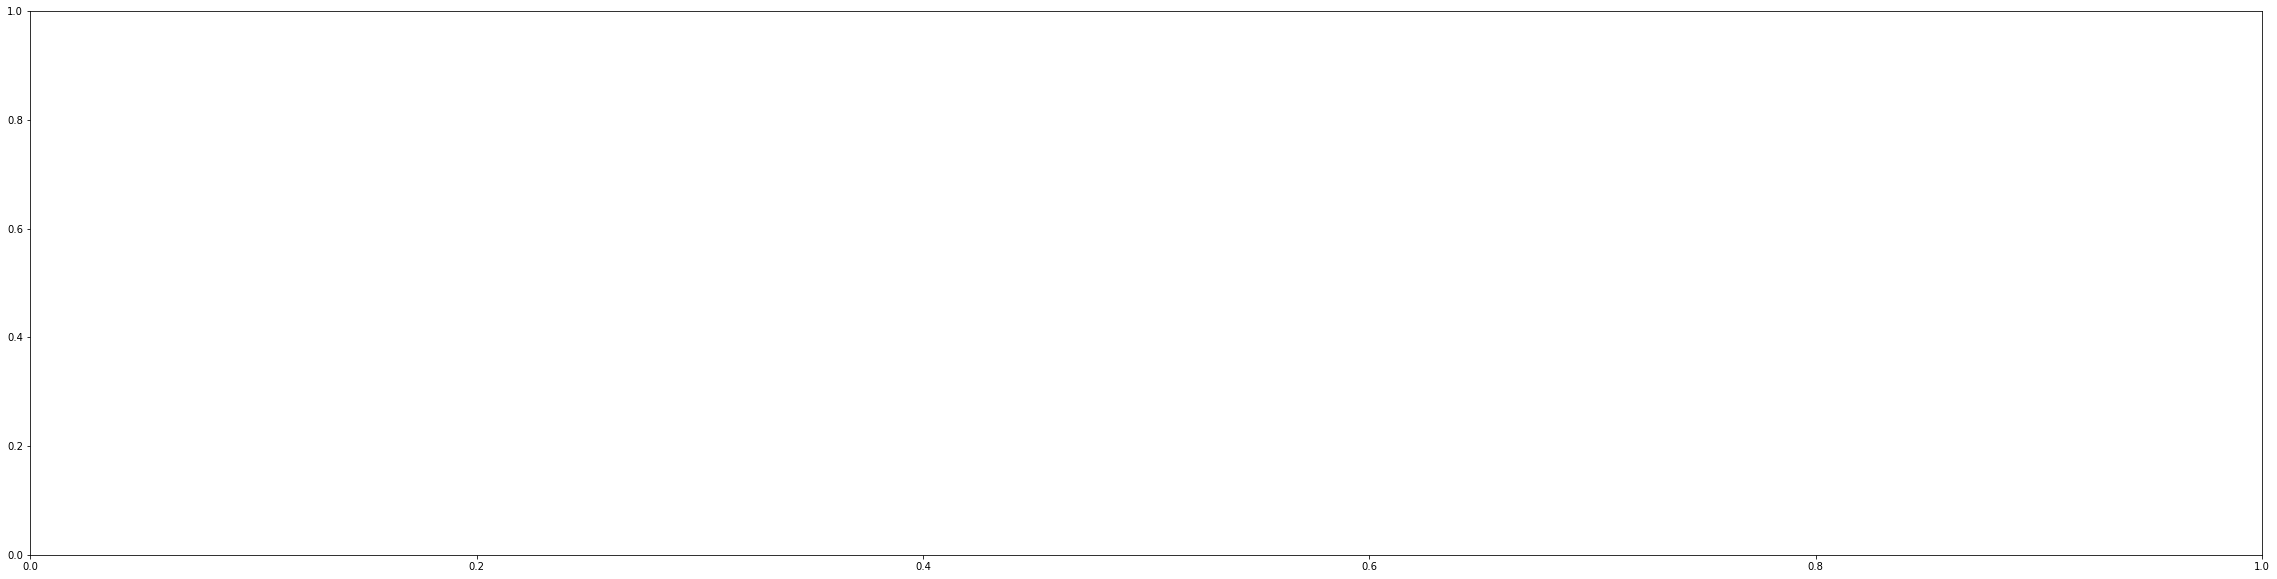

In [57]:
width = 0.8       # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(40, 10))
labels = specific_gene_plot.protein2_pref

ax.bar(labels, specific_gene_plot.experimental, width, label='Experimental')
ax.bar(labels, specific_gene_plot.database, width, bottom=specific_gene_plot.experimental,
       label='Database')
ax.bar(labels, specific_gene_plot.coexpression, width, bottom=specific_gene_plot.experimental+specific_gene_plot.database,
       label='Coexpression')
ax.bar(labels, specific_gene_plot.textmining, width, bottom=specific_gene_plot.experimental+specific_gene_plot.database + specific_gene_plot.coexpression,
       label='Textmining')
ax.bar(labels, specific_gene_plot.fusion, width, bottom=specific_gene_plot.experimental+specific_gene_plot.database + specific_gene_plot.coexpression + specific_gene_plot.textmining,
       label='Fusion')
ax.bar(labels, specific_gene_plot.neighborhood, width, bottom=specific_gene_plot.experimental+specific_gene_plot.database + specific_gene_plot.coexpression + specific_gene_plot.textmining + specific_gene_plot.fusion,
       label='Neighborhood')

ax.set_ylabel('Scores')
ax.set_title(gene + ' Scores by Channel')
ax.legend()

plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_' + gene + '-top50-sum-barplot.png')

In [124]:
labels

protein1
9606.ENSP00000367747    PIP5KL1
9606.ENSP00000367747    PIP5K1B
9606.ENSP00000367747    PIP5K1C
9606.ENSP00000367747    PIP5K1A
9606.ENSP00000367747    PIP4K2A
9606.ENSP00000367747    PIP4K2C
9606.ENSP00000367747     INPP5E
9606.ENSP00000367747     INPP5B
9606.ENSP00000367747      SYNJ2
9606.ENSP00000367747      SYNJ1
9606.ENSP00000367747     INPP5A
9606.ENSP00000367747       OCRL
9606.ENSP00000367747       IPMK
9606.ENSP00000367747      ITPKA
9606.ENSP00000367747     INPP5J
9606.ENSP00000367747     INPP5K
9606.ENSP00000367747     PIK3CD
9606.ENSP00000367747      ITPKB
9606.ENSP00000367747     PIK3CA
9606.ENSP00000367747     PIK3CB
9606.ENSP00000367747     PIK3CG
9606.ENSP00000367747      ITPKC
9606.ENSP00000367747      PLCG1
9606.ENSP00000367747      PLCG2
9606.ENSP00000367747       PTEN
9606.ENSP00000367747     MINPP1
9606.ENSP00000367747      PLCD1
9606.ENSP00000367747      PLCE1
9606.ENSP00000367747      PLCH1
9606.ENSP00000367747      PLCD3
9606.ENSP00000367747     PLA2R1

In [125]:
global prior 
prior = 0.041

def compute_prior_away(score):
    score = score/1000

    if score < prior: score = prior
    score_no_prior = (score - prior) / (1 - prior)

    return score_no_prior

In [126]:
neighborhood_prior_removed = specific_gene_df.textmining.apply(compute_prior_away)

In [127]:
neighborhood_prior_removed

protein1
9606.ENSP00000367747    0.411887
9606.ENSP00000367747    0.344108
9606.ENSP00000367747    0.201251
9606.ENSP00000367747    0.225235
9606.ENSP00000367747    0.101147
                          ...   
9606.ENSP00000367747    0.000000
9606.ENSP00000367747    0.057351
9606.ENSP00000367747    0.045881
9606.ENSP00000367747    0.000000
9606.ENSP00000367747    0.006257
Name: textmining, Length: 873, dtype: float64

In [128]:
channels = ['neighborhood', 'fusion', 'cooccurence', 'coexpression', 'experimental', 'database', 'textmining']

# 1-combined_score = channel_prod

# channel_score / channel_prod = fraction


temp_combined_score = 1-((specific_gene_plot['combined_score'].divide(1000)*(1-prior)))
# print(temp_combined_score)


processed_neighborhood = 1-(specific_gene_plot['neighborhood'].apply(compute_prior_away))
# print(processed_neighborhood)

processed_fusion = 1-(specific_gene_plot['fusion'].apply(compute_prior_away))
# print(processed_fusion)

processed_cooccurence = 1-(specific_gene_plot['cooccurence'].apply(compute_prior_away))
# print(processed_cooccurence)

processed_coexpression = 1-(specific_gene_plot['coexpression'].apply(compute_prior_away))
# print(processed_coexpression)

processed_experimental = 1-(specific_gene_plot['experimental'].apply(compute_prior_away))
# print(processed_experimental)

processed_database = 1-(specific_gene_plot['database'].apply(compute_prior_away))
# print(processed_database)

processed_textmining = 1-(specific_gene_plot['textmining'].apply(compute_prior_away))
# print(processed_textmining)



neighborhood_fraction = processed_neighborhood / temp_combined_score 
fusion_fraction = processed_fusion / temp_combined_score 
cooccurence_fraction = processed_cooccurence / temp_combined_score 
coexpression_fraction = processed_coexpression / temp_combined_score 
experimental_fraction = processed_experimental / temp_combined_score 
database_fraction = processed_database / temp_combined_score
textmining_fraction = processed_textmining / temp_combined_score 


# print(temp_combined_score)
# print(processed_textmining)

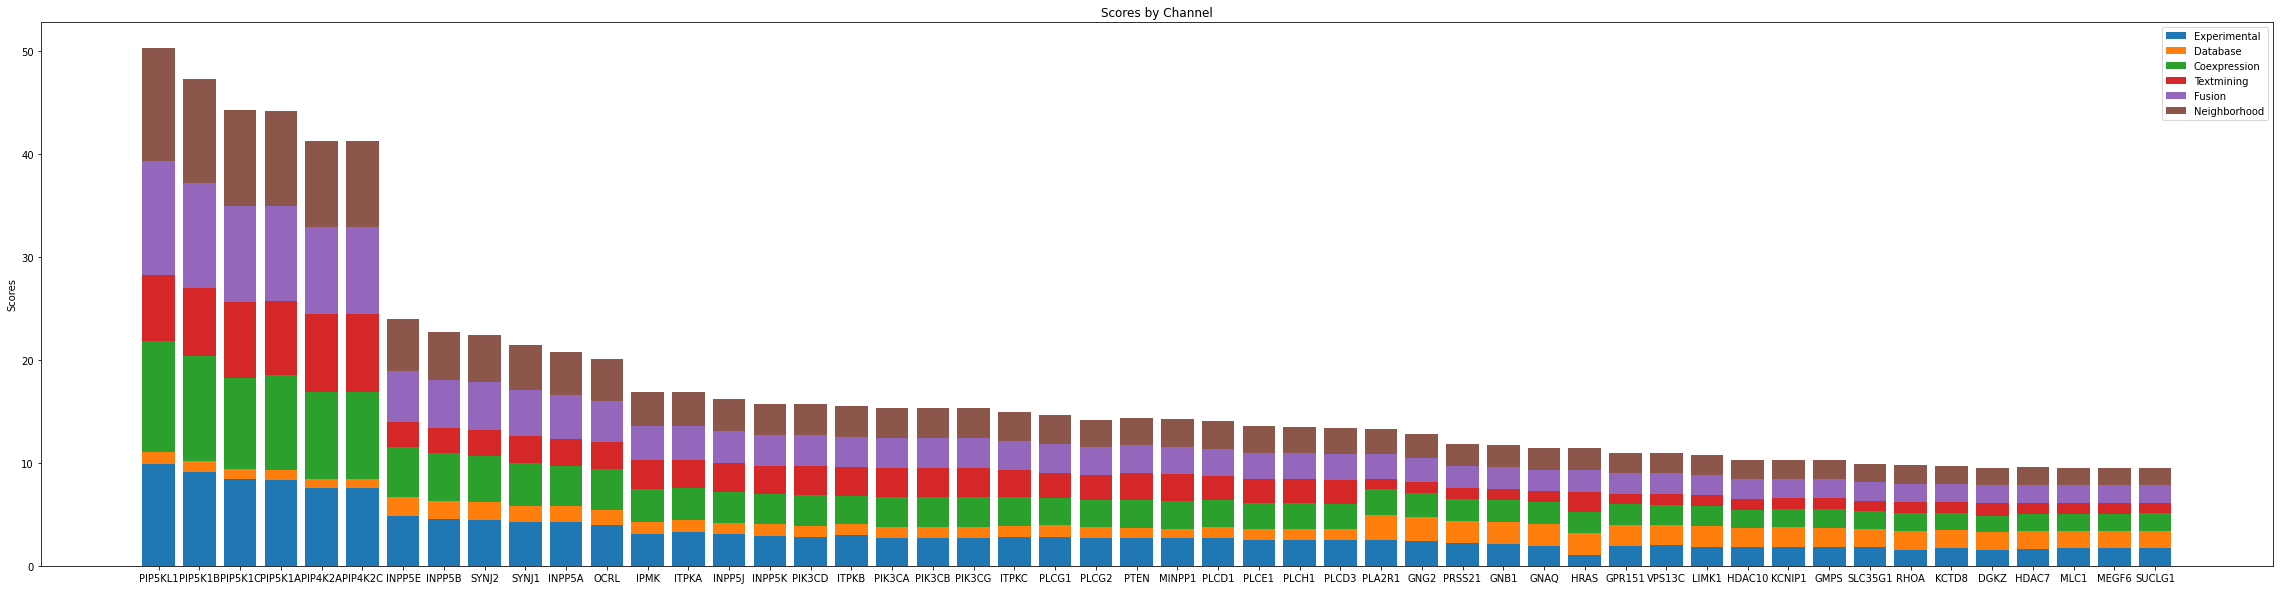

In [130]:
width = 0.8       # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(40, 10))
labels = specific_gene_plot.protein2_pref

ax.bar(labels, experimental_fraction, width, label='Experimental')
ax.bar(labels, database_fraction, width, bottom=experimental_fraction,
       label='Database')
ax.bar(labels, coexpression_fraction, width, bottom=experimental_fraction+database_fraction,
       label='Coexpression')
ax.bar(labels, textmining_fraction, width, bottom=experimental_fraction+database_fraction + coexpression_fraction,
       label='Textmining')
ax.bar(labels, fusion_fraction, width, bottom=experimental_fraction+database_fraction + coexpression_fraction + textmining_fraction,
       label='Fusion')
ax.bar(labels, neighborhood_fraction, width, bottom=experimental_fraction+database_fraction + coexpression_fraction + textmining_fraction + fusion_fraction,
       label='Neighborhood')

ax.set_ylabel('Scores')
ax.set_title('Scores by Channel')
ax.legend()

plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_' + gene + '-top50-product-barplot.png')

In [ ]:
total = processed_neighborhood + processed_fusion + processed_cooccurence + processed_coexpression + processed_experimental = 1-(specific_gene_plot['experimental'].apply(compute_prior_away))
+ processed_database

# Find closest gene

In [20]:
gene_df_no_dupes['midpoint'] = (gene_df_no_dupes['end'] + gene_df_no_dupes['start']) // 2
print(gene_df_no_dupes['midpoint'])

gene_names
DDX11L1        13138
WASH7P         21986
MIR1302-2HG    30325
MIR1302-2      30434
FAM138A        35317
               ...  
ND6            14410
MT-TE          14707
CYTB           15316
MT-TT          15920
MT-TP          15989
Name: midpoint, Length: 51806, dtype: int64


/tmp/ipykernel_143653/4027052627.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gene_df_no_dupes['midpoint'] = (gene_df_no_dupes['end'] + gene_df_no_dupes['start']) // 2


In [21]:
gene_df_no_dupes

,chr,start,end,4,strand,6,7,8,descriptor,10,11,12,13,midpoint
gene_names,,,,,,,,,,,,,,
DDX11L1,chr1,11868,14409,0,+,ENST00000456328,37102,pseudo,DEAD/H-box helicase 11 like 1,14409,14409,"359,109,1189,","0,744,1352,",13138
WASH7P,chr1,14403,29570,0,-,ENST00000488147,38034,pseudo,"WASP family homolog 7, pseudogene",29570,29570,"98,34,152,159,198,136,137,147,99,154,37,","0,601,1392,2203,2454,2829,3202,3511,3864,10334...",21986
MIR1302-2HG,chr1,29553,31097,0,+,ENST00000473358,.,.,MIR1302-2 host gene,31097,31097,"486,104,122,","0,1010,1422,",30325
MIR1302-2,chr1,30365,30503,0,+,ENST00000607096,35294,ncRNA,microRNA 1302-2,30503,30503,"138,","0,",30434
FAM138A,chr1,34553,36081,0,-,ENST00000417324,32334,ncRNA,family with sequence similarity 138 member A,36081,36081,"621,205,361,","0,723,1167,",35317
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ND6,chrM,14148,14673,29,-,ENST00000361681,7462,protein-coding,"NADH dehydrogenase, subunit 6 (complex I)",14148,14673,"525,","0,",14410
MT-TE,chrM,14673,14742,0,-,ENST00000387459,.,.,mitochondrially encoded tRNA glutamic acid,14742,14742,"69,","0,",14707
CYTB,chrM,14746,15887,24,+,ENST00000361789,7427,protein-coding,cytochrome b,14746,15887,"1141,","0,",15316
